# Sentiment Classification Model Training and Evaluation

## Objective

This notebook trains and evaluates machine learning models for sentiment classification using energy app review text.

The models trained in this notebook are:

1. CountVectorizer + Multinomial Naive Bayes
2. TF-IDF + Logistic Regression

The models are evaluated using:

- Accuracy
- Precision
- Recall
- F1-score
- Confusion matrix

The goal is to compare a simple probabilistic text classifier with a stronger linear classification model.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 120)

REPORTS_DIR = Path("../reports")
FIGURES_DIR = Path("../reports/figures")
MODELS_DIR = Path("../models")

REPORTS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
data_path = "../data/processed/energy_app_reviews_cleaned.csv"

df = pd.read_csv(data_path)

print("Dataset shape:", df.shape)
df[["app_name", "rating", "sentiment", "clean_review_text"]].head()

Dataset shape: (3070, 14)


,app_name,rating,sentiment,clean_review_text
0,Octopus Electroverse,4,Positive,good app map always default charing cross would better choice default home last used
1,Octopus Electroverse,5,Positive,fantastic
2,Octopus Electroverse,5,Positive,honest say decided go electric car nervous regarding charging network support however installing app game changer re...
3,Octopus Electroverse,5,Positive,app seems fine support excellent problem account able log could reply email answer human sorted thanks ryan l
4,Octopus Electroverse,5,Positive,easy fast use also cover wide range charge point


In [3]:
X = df["clean_review_text"]
y = df["sentiment"]

print("Number of reviews:", len(X))

print("\nSentiment distribution:")
print(y.value_counts())

Number of reviews: 3070

Sentiment distribution:
sentiment
Negative    1439
Positive    1411
Neutral      220
Name: count, dtype: int64


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("\nTraining sentiment distribution:")
print(y_train.value_counts())

print("\nTesting sentiment distribution:")
print(y_test.value_counts())

Training samples: 2456
Testing samples: 614

Training sentiment distribution:
sentiment
Negative    1151
Positive    1129
Neutral      176
Name: count, dtype: int64

Testing sentiment distribution:
sentiment
Negative    288
Positive    282
Neutral      44
Name: count, dtype: int64


In [5]:
custom_stopwords = [
    "app",
    "apps",
    "nu",
    "sa",
    "la",
    "si",
    "de"
]

In [6]:
count_nb_pipeline = Pipeline(
    steps=[
        (
            "vectorizer",
            CountVectorizer(
                max_features=5000,
                ngram_range=(1, 2),
                min_df=3,
                max_df=0.90,
                stop_words=custom_stopwords,
                token_pattern=r"(?u)\b[a-zA-Z]{2,}\b"
            )
        ),
        (
            "model",
            MultinomialNB()
        )
    ]
)

tfidf_logreg_pipeline = Pipeline(
    steps=[
        (
            "vectorizer",
            TfidfVectorizer(
                max_features=5000,
                ngram_range=(1, 2),
                min_df=3,
                max_df=0.90,
                stop_words=custom_stopwords,
                token_pattern=r"(?u)\b[a-zA-Z]{2,}\b"
            )
        ),
        (
            "model",
            LogisticRegression(
                max_iter=1000,
                class_weight="balanced",
                random_state=42
            )
        )
    ]
)

print("Model pipelines created successfully.")

Model pipelines created successfully.


In [7]:
print("Training CountVectorizer + Naive Bayes model...")

count_nb_pipeline.fit(X_train, y_train)

print("Training completed.")

Training CountVectorizer + Naive Bayes model...
Training completed.


In [8]:
print("Training TF-IDF + Logistic Regression model...")

tfidf_logreg_pipeline.fit(X_train, y_train)

print("Training completed.")

Training TF-IDF + Logistic Regression model...
Training completed.


In [9]:
y_pred_count_nb = count_nb_pipeline.predict(X_test)
y_pred_tfidf_logreg = tfidf_logreg_pipeline.predict(X_test)

print("Predictions completed.")

Predictions completed.


In [10]:
def evaluate_model(model_name, y_true, y_pred):
    """
    Evaluate a classification model and return key metrics.
    """

    accuracy = accuracy_score(y_true, y_pred)

    precision_macro = precision_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    recall_macro = recall_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    f1_macro = f1_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    f1_weighted = f1_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )

    return {
        "model_name": model_name,
        "accuracy": accuracy,
        "macro_precision": precision_macro,
        "macro_recall": recall_macro,
        "macro_f1": f1_macro,
        "weighted_f1": f1_weighted
    }

In [11]:
model_results = []

model_results.append(
    evaluate_model(
        "CountVectorizer + Naive Bayes",
        y_test,
        y_pred_count_nb
    )
)

model_results.append(
    evaluate_model(
        "TF-IDF + Logistic Regression",
        y_test,
        y_pred_tfidf_logreg
    )
)

results_df = pd.DataFrame(model_results)

results_df

,model_name,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1
0,CountVectorizer + Naive Bayes,0.806189,0.654281,0.597959,0.595963,0.785474
1,TF-IDF + Logistic Regression,0.765472,0.614494,0.620124,0.615214,0.773560


In [12]:
results_df.to_csv("../reports/sentiment_model_results.csv", index=False)

print("Model results saved to ../reports/sentiment_model_results.csv")

Model results saved to ../reports/sentiment_model_results.csv


In [13]:
print("Classification Report: CountVectorizer + Naive Bayes")
print(classification_report(y_test, y_pred_count_nb, zero_division=0))

Classification Report: CountVectorizer + Naive Bayes
              precision    recall  f1-score   support

    Negative       0.79      0.89      0.84       288
     Neutral       0.33      0.07      0.11        44
    Positive       0.84      0.83      0.83       282

    accuracy                           0.81       614
   macro avg       0.65      0.60      0.60       614
weighted avg       0.78      0.81      0.79       614



In [14]:
report_count_nb = classification_report(
    y_test,
    y_pred_count_nb,
    output_dict=True,
    zero_division=0
)

report_count_nb_df = pd.DataFrame(report_count_nb).transpose()

report_count_nb_df.to_csv(
    "../reports/classification_report_count_nb_sentiment.csv"
)

report_count_nb_df

,precision,recall,f1-score,support
Negative,0.793210,0.892361,0.839869,288.000000
Neutral,0.333333,0.068182,0.113208,44.000000
Positive,0.836299,0.833333,0.834813,282.000000
accuracy,0.806189,0.806189,0.806189,0.806189
macro avg,0.654281,0.597959,0.595963,614.000000
weighted avg,0.780045,0.806189,0.785474,614.000000


In [15]:
print("Classification Report: TF-IDF + Logistic Regression")
print(classification_report(y_test, y_pred_tfidf_logreg, zero_division=0))

Classification Report: TF-IDF + Logistic Regression
              precision    recall  f1-score   support

    Negative       0.80      0.81      0.81       288
     Neutral       0.18      0.25      0.21        44
    Positive       0.86      0.80      0.83       282

    accuracy                           0.77       614
   macro avg       0.61      0.62      0.62       614
weighted avg       0.78      0.77      0.77       614



In [16]:
report_tfidf_logreg = classification_report(
    y_test,
    y_pred_tfidf_logreg,
    output_dict=True,
    zero_division=0
)

report_tfidf_logreg_df = pd.DataFrame(report_tfidf_logreg).transpose()

report_tfidf_logreg_df.to_csv(
    "../reports/classification_report_tfidf_logreg_sentiment.csv"
)

report_tfidf_logreg_df

,precision,recall,f1-score,support
Negative,0.801370,0.812500,0.806897,288.000000
Neutral,0.183333,0.250000,0.211538,44.000000
Positive,0.858779,0.797872,0.827206,282.000000
accuracy,0.765472,0.765472,0.765472,0.765472
macro avg,0.614494,0.620124,0.615214,614.000000
weighted avg,0.783447,0.765472,0.773560,614.000000


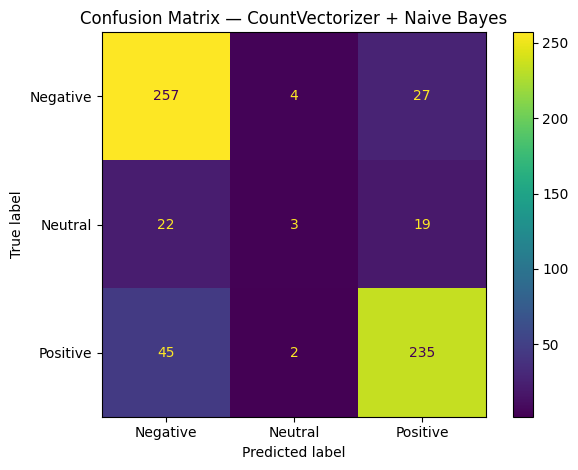

In [17]:
labels = ["Negative", "Neutral", "Positive"]

cm_count_nb = confusion_matrix(
    y_test,
    y_pred_count_nb,
    labels=labels
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_count_nb,
    display_labels=labels
)

disp.plot(values_format="d")
plt.title("Confusion Matrix — CountVectorizer + Naive Bayes")
plt.tight_layout()

plt.savefig(
    "../reports/figures/confusion_matrix_count_nb_sentiment.png",
    dpi=300
)

plt.show()

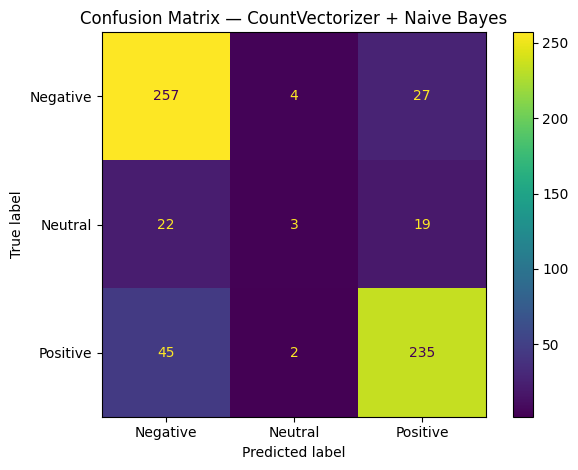

In [18]:
labels = ["Negative", "Neutral", "Positive"]

cm_count_nb = confusion_matrix(
    y_test,
    y_pred_count_nb,
    labels=labels
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_count_nb,
    display_labels=labels
)

disp.plot(values_format="d")
plt.title("Confusion Matrix — CountVectorizer + Naive Bayes")
plt.tight_layout()

plt.savefig(
    "../reports/figures/confusion_matrix_count_nb_sentiment.png",
    dpi=300
)

plt.show()

In [19]:
joblib.dump(
    count_nb_pipeline,
    "../models/count_nb_sentiment_model.pkl"
)

joblib.dump(
    tfidf_logreg_pipeline,
    "../models/tfidf_logreg_sentiment_model.pkl"
)

print("Models saved successfully.")

Models saved successfully.


In [20]:
example_reviews = [
    "The charging station worked perfectly and the app was very easy to use.",
    "I cannot log in and the payment keeps failing every time.",
    "The service is okay but the app needs some improvements."
]

example_predictions = pd.DataFrame({
    "review": example_reviews,
    "count_nb_prediction": count_nb_pipeline.predict(example_reviews),
    "tfidf_logreg_prediction": tfidf_logreg_pipeline.predict(example_reviews)
})

example_predictions

,review,count_nb_prediction,tfidf_logreg_prediction
0,The charging station worked perfectly and the app was very easy to use.,Positive,Positive
1,I cannot log in and the payment keeps failing every time.,Negative,Negative
2,The service is okay but the app needs some improvements.,Positive,Neutral


## Model Training Observations

Two sentiment classification models were trained and compared.

The CountVectorizer + Naive Bayes model provides a fast and interpretable baseline. It uses raw word and phrase counts to classify review sentiment.

The TF-IDF + Logistic Regression model uses weighted text features and a linear classifier. TF-IDF reduces the influence of very common terms and often improves classification performance for text data.

Because the neutral class is smaller than the positive and negative classes, macro F1-score is important in addition to accuracy. Accuracy gives the overall correctness, while macro F1 gives a better view of how well the model performs across all sentiment classes.

The confusion matrices help identify which classes are most often confused by the models.